# Taylor Series and π Approximation with SymPy

## Learning objectives

By the end of this notebook you will be able to:

1. Compute symbolic Taylor expansions with `sympy.series`
2. Manipulate series: differentiate, substitute, and remove remainder terms
3. Derive the **Leibniz–Gregory** formula for π from `arctan`
4. Measure convergence speed and understand why the series is slow
5. Apply **Machin's formula** for dramatically faster π approximation
6. Appreciate SymPy's exact arithmetic vs floating-point evaluation

---

### Mathematical background

The Taylor expansion of $\arctan(x)$ around $x = 0$ is:

$$\arctan(x) = x - \frac{x^3}{3} + \frac{x^5}{5} - \frac{x^7}{7} + \cdots = \sum_{k=0}^{\infty} \frac{(-1)^k}{2k+1} x^{2k+1}$$

Setting $x = 1$ gives the **Leibniz–Gregory** series:

$$\frac{\pi}{4} = 1 - \frac{1}{3} + \frac{1}{5} - \frac{1}{7} + \cdots$$

**Machin's formula** (1706) converges much faster:

$$\frac{\pi}{4} = 4\arctan\!\left(\frac{1}{5}\right) - \arctan\!\left(\frac{1}{239}\right)$$

## Setup — install and import SymPy

In [1]:
from sympy import (symbols, atan, tan, series, diff, simplify, expand_trig,
                   Rational, pi, Abs, log, floor, init_printing)

init_printing()       # display results as real fractions / LaTeX
x = symbols('x')      # x is a mathematical symbol, not a number

---
## Part 1 — Symbolic Taylor expansion

### Exercise 1.1 — Compute the series

Use `sympy.series(f, x, x0, n)` to expand $\arctan(x)$ around $x_0 = 0$ up to (but not including) order $n = 15$.

> **Expected result:**  
> $x - \dfrac{x^3}{3} + \dfrac{x^5}{5} - \dfrac{x^7}{7} + \dfrac{x^9}{9} - \dfrac{x^{11}}{11} + \dfrac{x^{13}}{13} + O(x^{15})$

In [2]:
# Exercise 1.1 - Taylor expansion of arctan(x) around 0, up to (not including) x**15
s = series(atan(x), x, 0, 15)

In [3]:
s   # only odd powers, alternating signs, plus the remainder O(x**15)

### Exercise 1.2 — Remove the remainder and verify at 0

Call `.removeO()` on the series to obtain a plain polynomial `p`. Then verify that $p(0) = 0$ by substituting `x = 0`.

In [4]:
# Exercise 1.2 - remove the remainder O(x**15) to get a plain polynomial
p = s.removeO()
p

In [5]:
# p(0) must be 0, like arctan(0)
p.subs(x, 0)

### Exercise 1.3 — Verify the derivative

The derivative of $\arctan(x)$ is $\dfrac{1}{1+x^2}$.  
Differentiate `p` with respect to `x` and compare it to the Taylor expansion of $\dfrac{1}{1+x^2}$ at the same order. Their difference should simplify to `0`.

In [6]:
# Exercise 1.3 - derivative of p, compared with the expansion of 1/(1+x**2)
dp = diff(p, x)                                    # stops at x**12
g = series(1 / (1 + x**2), x, 0, 14).removeO()     # order 14 so that it also stops at x**12
dp, g

In [7]:
simplify(dp - g)   # 0: the derivative of the polynomial matches 1/(1+x**2)

---
## Part 2 — Approximating π with the Leibniz–Gregory series

### Exercise 2.1 — First approximation

Substitute $x = 1$ into the polynomial `p` from Exercise 1.2.  
You get a rational approximation of $\pi/4$.  
Multiply by 4 and call `.evalf(50)` to see 50 decimal places.  
Compare to `pi.evalf(50)` — how many digits are correct?

In [8]:
# Exercise 2.1 - x = 1 gives a rational approximation of pi/4 (Leibniz-Gregory)
approx = 4 * p.subs(x, 1)
approx     # exact fraction: no rounding error yet

In [9]:
print('approximation:', approx.evalf(50))
print('true pi      :', pi.evalf(50))
print('correct decimal digits:', int(floor(-log(Abs(approx - pi), 10)).evalf()))
# Only 0 correct decimal digit: 7 terms are far from enough.

approximation: 3.2837384837384837384837384837384837384837384837385
true pi      : 3.1415926535897932384626433832795028841971693993751
correct decimal digits: 0


### Exercise 2.2 — Convergence table

Write a loop over odd orders $n = 1, 3, 5, \ldots, 29$.  
For each order, compute the approximation and count the number of correct decimal digits using:

$$\text{digits} = \lfloor -\log_{10}|\text{approx} - \pi| \rfloor$$

Print a table. Observe how slowly the series converges.

In [10]:
# Exercise 2.2 - number of correct digits: floor(-log10 |approx - pi|)
def correct_digits(value):
    return int(floor(-log(Abs(value - pi), 10)).evalf(30))

def leibniz(n):
    """4 * Taylor polynomial of arctan of order n, evaluated at x = 1."""
    return 4 * series(atan(x), x, 0, n).removeO().subs(x, 1)

In [11]:
print(f"{'order n':>8} {'approximation':>24} {'correct digits':>15}")
for n in range(1, 30, 2):
    a = leibniz(n)
    print(f"{n:>8} {str(a.evalf(20)):>24} {correct_digits(a):>15}")
# The number of correct digits barely moves: the error decreases like 1/n.

 order n            approximation  correct digits
       1                        0              -1
       3    4.0000000000000000000               0
       5    2.6666666666666666667               0
       7    3.4666666666666666667               0
       9    2.8952380952380952381               0
      11    3.3396825396825396825               0


      13    2.9760461760461760462               0
      15    3.2837384837384837385               0
      17    3.0170718170718170718               0


      19    3.2523659347188758953               0
      21    3.0418396189294022111               1
      23    3.2323158094055926873               1


      25    3.0584027659273318178               1
      27    3.2184027659273318178               1


      29    3.0702546177791836696               1


### Reflection

**Why is the Leibniz series so slow?**  
The general term is $\dfrac{(-1)^k}{2k+1}$. Its absolute value decays like $\dfrac{1}{2k+1}$ — only polynomially fast. After $N$ terms the error is approximately $\dfrac{1}{2N+1}$, so you need about $10^d$ terms to gain $d$ decimal digits. That is impractical for more than a few digits.

---
## Part 3 — Machin's formula (bonus)

$$\frac{\pi}{4} = 4\arctan\!\left(\frac{1}{5}\right) - \arctan\!\left(\frac{1}{239}\right)$$

### Exercise 3.1 — Verify the formula symbolically

Use `simplify` or `trigsimp` to confirm that the expression equals $\pi/4$ exactly in SymPy.  
The result should be `True` when compared to zero.

In [12]:
# Exercise 3.1 - Machin's formula: 4*arctan(1/5) - arctan(1/239) = pi/4
machin = 4 * atan(Rational(1, 5)) - atan(Rational(1, 239))
simplify(machin - pi / 4)   # simplify alone cannot close it in this SymPy version (stays unevaluated)

# Exact check through the tangent: expand tan(4a - b) with the addition formulas,
# then put tan(a) = 1/5 and tan(b) = 1/239.
a, b = symbols('a b')
tan_machin = simplify(expand_trig(tan(4 * a - b)).subs({tan(a): Rational(1, 5), tan(b): Rational(1, 239)}))
tan_machin   # 1, and tan(pi/4) = 1

In [13]:
# tan(machin) = 1 and machin lies in (-pi/2, pi/2), where tan is one-to-one: so machin = pi/4 exactly
in_range = bool(machin > -pi / 2) and bool(machin < pi / 2)
tan_machin == 1 and in_range   # True

True

### Exercise 3.2 — Machin convergence table

Repeat the loop from Exercise 2.2, but this time approximate `arctan(1/5)` and `arctan(1/239)` using the truncated Taylor polynomial of order `n`, then apply Machin's formula. Print the same convergence table and compare.

In [14]:
# Exercise 3.2 - same polynomial, but evaluated at 1/5 and 1/239 (Machin)
def machin_approx(n):
    poly = series(atan(x), x, 0, n).removeO()
    return 4 * (4 * poly.subs(x, Rational(1, 5)) - poly.subs(x, Rational(1, 239)))

In [15]:
print(f"{'order n':>8} {'approximation':>24} {'correct digits':>15}")
for n in range(1, 30, 2):
    a = machin_approx(n)
    print(f"{n:>8} {str(a.evalf(20)):>24} {correct_digits(a):>15}")
# About 1.4 more correct digits for each extra term: exponential convergence.

 order n            approximation  correct digits
       1                        0              -1
       3    3.1832635983263598326               1


       5    3.1405970293260603143               3
       7    3.1416210293250344250               4


       9    3.1415917721821772950               6
      11    3.1415926824043995172               7


      13    3.1415926526153086082               9
      15    3.1415926536235547620              10


      17    3.1415926535886022287              11
      19    3.1415926535898358475              13


      21    3.1415926535897916969              14


      23    3.1415926535897932947              16
      25    3.1415926535897932364              17


      27    3.1415926535897932385              19


      29    3.1415926535897932385              20


### Reflection — why is Machin so much faster?

When you evaluate the Taylor polynomial at $x = \tfrac{1}{5}$, successive terms shrink by a factor of $\left(\tfrac{1}{5}\right)^2 = \tfrac{1}{25}$ per step — **exponential convergence**. After $n$ terms the error is roughly $\dfrac{(1/5)^{2n+1}}{2n+1}$.

For $\arctan(1/239)$ the decay is even faster: $(1/239)^2 \approx 1.75 \times 10^{-5}$ per step.

| Series | Terms for 10 digits | Terms for 20 digits |
|--------|--------------------:|--------------------:|
| Leibniz $x=1$ | ~5 billion | ~50 billion |
| Machin $x=1/5$ | ~7 | ~14 |

---
## Part 4 — Side-by-side comparison (visualisation)

Plot the number of correct digits as a function of order for both methods on the same axes.

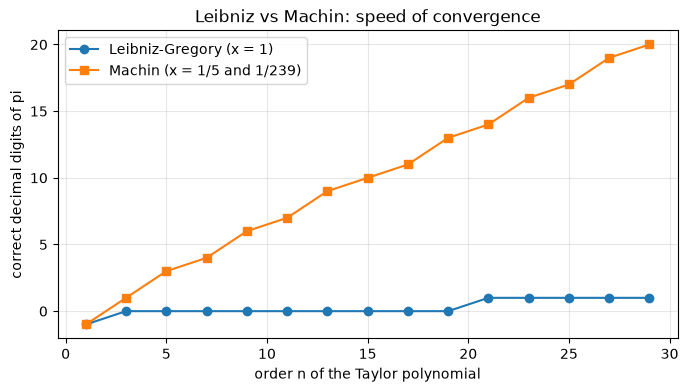

In [16]:
# Part 4 - correct digits for both methods, same orders
import matplotlib.pyplot as plt

orders = list(range(1, 30, 2))
digits_leibniz = [correct_digits(leibniz(n)) for n in orders]
digits_machin = [correct_digits(machin_approx(n)) for n in orders]

plt.figure(figsize=(8, 4))
plt.plot(orders, digits_leibniz, 'o-', label='Leibniz-Gregory (x = 1)')
plt.plot(orders, digits_machin, 's-', label='Machin (x = 1/5 and 1/239)')
plt.xlabel('order n of the Taylor polynomial')
plt.ylabel('correct decimal digits of pi')
plt.title('Leibniz vs Machin: speed of convergence')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Summary

| Concept | What you practiced |
|---------|-------------------|
| `sympy.series` | Symbolic Taylor expansion with automatic big-O remainder |
| `.removeO()` | Strip the remainder to get a workable polynomial |
| `diff` + `simplify` | Verify the derivative identity symbolically |
| `.subs` + `.evalf` | Evaluate exactly in rationals, then convert to decimals |
| Leibniz–Gregory | $\pi/4 = \arctan(1)$ — correct but very slowly converging |
| Machin's formula | Decomposes $\arctan(1)$ into two fast-converging series |
| Exact arithmetic | SymPy accumulates no floating-point error until `.evalf()` |

---

### Going further

- **Chudnovsky algorithm** — the series used by modern π-computation records; converges at ~14 digits per term.
- `SymPy.mpmath` — arbitrary-precision numerics built into SymPy, with `mp.nstr(mp.pi, 1000)` for high-precision work.
- **Error bounding** — use SymPy's interval arithmetic or `series` remainder term to prove rigorous error bounds, not just empirical digit counts.